In [ ]:

from google.colab import files

uploaded = files.upload()



Saving MalMem2022.csv to MalMem2022.csv


In [ ]:

import pandas as pd

file_name = list(uploaded.keys())[0]
df = pd.read_csv(file_name)

print("Dataset Loaded Successfully!")
print("File Name:", file_name)
print("Dataset Shape:", df.shape)

display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nCategory Distribution:")
print(df['Category'].value_counts())


Dataset Loaded Successfully!
File Name: MalMem2022.csv
Dataset Shape: (58596, 58)


,pslist.nproc,pslist.nppid,pslist.avg_threads,pslist.nprocs64bit,pslist.avg_handlers,dlllist.ndlls,dlllist.avg_dlls_per_proc,handles.nhandles,handles.avg_handles_per_proc,handles.nport,...,svcscan.process_services,svcscan.shared_process_services,svcscan.interactive_process_services,svcscan.nactive,callbacks.ncallbacks,callbacks.nanonymous,callbacks.ngeneric,Class,Category,Filename
0,45,17,10.555556,0,202.844444,1694,38.500000,9129,212.302326,0,...,24,116,0,121,87,0,8,Benign,Benign,Benign
1,47,19,11.531915,0,242.234043,2074,44.127660,11385,242.234043,0,...,24,118,0,122,87,0,8,Benign,Benign,Benign
2,40,14,14.725000,0,288.225000,1932,48.300000,11529,288.225000,0,...,27,118,0,120,88,0,8,Benign,Benign,Benign
3,32,13,13.500000,0,264.281250,1445,45.156250,8457,264.281250,0,...,27,118,0,120,88,0,8,Benign,Benign,Benign
4,42,16,11.452381,0,281.333333,2067,49.214286,11816,281.333333,0,...,24,118,0,124,87,0,8,Benign,Benign,Benign



Column Names:
['pslist.nproc', 'pslist.nppid', 'pslist.avg_threads', 'pslist.nprocs64bit', 'pslist.avg_handlers', 'dlllist.ndlls', 'dlllist.avg_dlls_per_proc', 'handles.nhandles', 'handles.avg_handles_per_proc', 'handles.nport', 'handles.nfile', 'handles.nevent', 'handles.ndesktop', 'handles.nkey', 'handles.nthread', 'handles.ndirectory', 'handles.nsemaphore', 'handles.ntimer', 'handles.nsection', 'handles.nmutant', 'ldrmodules.not_in_load', 'ldrmodules.not_in_init', 'ldrmodules.not_in_mem', 'ldrmodules.not_in_load_avg', 'ldrmodules.not_in_init_avg', 'ldrmodules.not_in_mem_avg', 'malfind.ninjections', 'malfind.commitCharge', 'malfind.protection', 'malfind.uniqueInjections', 'psxview.not_in_pslist', 'psxview.not_in_eprocess_pool', 'psxview.not_in_ethread_pool', 'psxview.not_in_pspcid_list', 'psxview.not_in_csrss_handles', 'psxview.not_in_session', 'psxview.not_in_deskthrd', 'psxview.not_in_pslist_false_avg', 'psxview.not_in_eprocess_pool_false_avg', 'psxview.not_in_ethread_pool_false_a

In [ ]:

# Check dataset information

print("Dataset Information")
print("-" * 40)

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nMissing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes.value_counts())



Dataset Information
----------------------------------------
Total Rows: 58596
Total Columns: 58

Missing Values: 0
Duplicate Rows: 534

Data Types:
int64      40
float64    15
object      3
Name: count, dtype: int64


In [ ]:
# Remove duplicate records
df_clean = df.drop_duplicates().copy()

print("Data Cleaning Completed!")
print("Original Records:", len(df))
print("Records After Removing Duplicates:", len(df_clean))
print("Duplicates Removed:", len(df) - len(df_clean))

Data Cleaning Completed!
Original Records: 58596
Records After Removing Duplicates: 58062
Duplicates Removed: 534


In [ ]:
print("Text Columns:")
print(df_clean.select_dtypes(include='object').columns.tolist())

print("\nAll Categories:")
print(df_clean['Category'].value_counts())

Text Columns:
['Class', 'Category', 'Filename']

All Categories:
Category
Benign                  29231
Spyware-Transponder      2410
Ransomware-Shade         2128
Spyware-180solutions     2000
Spyware-CWS              2000
Trojan-Scar              2000
Trojan-Refroso           2000
Ransomware-Ako           2000
Spyware-Gator            1995
Ransomware-Conti         1988
Trojan-Emotet            1967
Trojan-Zeus              1950
Ransomware-Maze          1754
Ransomware-Pysa          1659
Trojan-Reconyc           1570
Spyware-TIBS             1410
Name: count, dtype: int64


In [ ]:

# Step 1: Create binary dataset

df_clean['Category'] = df_clean['Category'].astype(str).str.strip()

# Step 2: Select Benign and Ransomware
df_binary = df_clean[
    (df_clean['Category'] == 'Benign') |
    (df_clean['Category'].str.startswith('Ransomware-', na=False))
].copy()

# Step 3: Assign numerical labels
df_binary['Target'] = (
    df_binary['Category'].str.startswith('Ransomware-', na=False)
).astype(int)

# Step 4: Display results
print("Binary Dataset Created Successfully!")

print("\nTotal Records:", len(df_binary))

print("\nClass Distribution:")
print(df_binary['Target'].value_counts())

print("\nCategory and Target:")
display(df_binary[['Category', 'Target']].head(10))


Binary Dataset Created Successfully!

Total Records: 38760

Class Distribution:
Target
0    29231
1     9529
Name: count, dtype: int64

Category and Target:


,Category,Target
0,Benign,0
1,Benign,0
2,Benign,0
3,Benign,0
4,Benign,0
5,Benign,0
6,Benign,0
7,Benign,0
8,Benign,0
9,Benign,0


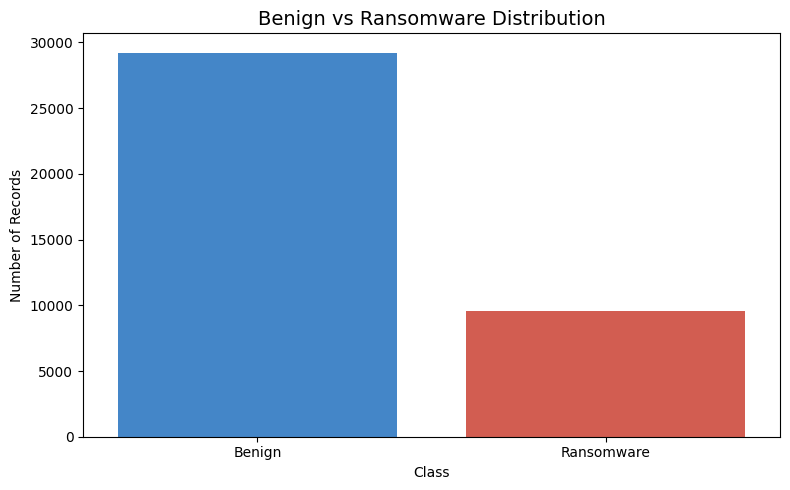

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_binary,
    x='Target',
    hue='Target',
    palette=['#2E86DE', '#E74C3C'],
    legend=False
)

plt.xticks([0, 1], ['Benign', 'Ransomware'])
plt.title('Benign vs Ransomware Distribution',
          fontsize=14)
plt.xlabel('Class')
plt.ylabel('Number of Records')

plt.tight_layout()
plt.savefig('class_distribution.png', dpi=300)
plt.show()


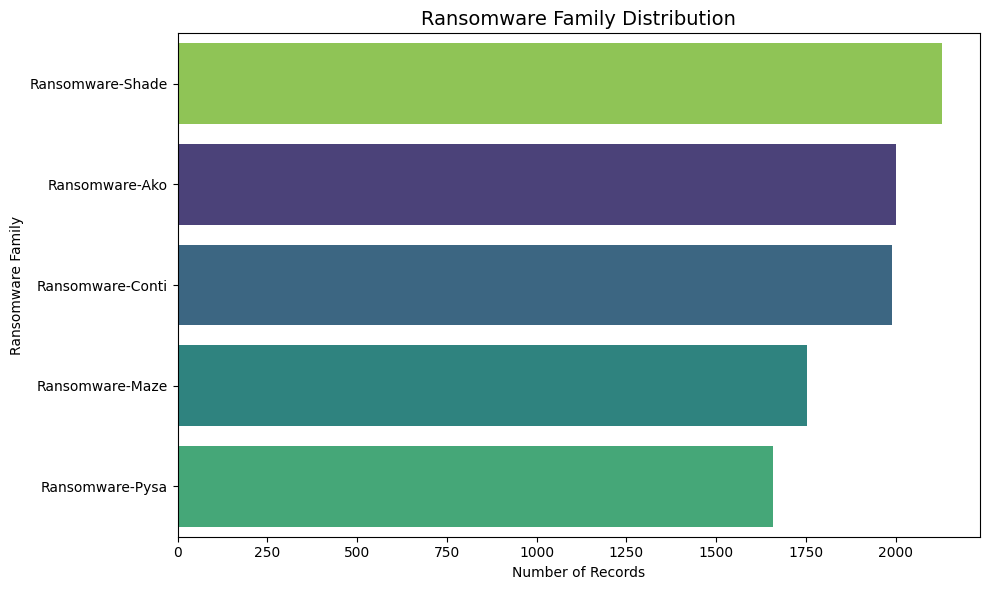

In [ ]:

ransomware_data = df_binary[
    df_binary['Target'] == 1
]

plt.figure(figsize=(10, 6))

sns.countplot(
    data=ransomware_data,
    y='Category',
    hue='Category',
    palette='viridis',
    legend=False,
    order=ransomware_data['Category'].value_counts().index
)

plt.title('Ransomware Family Distribution',
          fontsize=14)
plt.xlabel('Number of Records')
plt.ylabel('Ransomware Family')

plt.tight_layout()
plt.savefig('ransomware_families.png', dpi=300)
plt.show()


In [ ]:

# STEP 6: FEATURE SELECTION

# Remove unnecessary columns
X = df_binary.drop(
    columns=['Class', 'Category', 'Filename', 'Target'],
    errors='ignore'
)

# Select only numerical behavioral features
X = X.select_dtypes(include=['number'])

# Store target variable
y = df_binary['Target']

print("FEATURE SELECTION COMPLETED!")
print("--------------------------------")

print("Total Records:", X.shape[0])
print("Total Features:", X.shape[1])

print("\nSelected Behavioral Features:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())


FEATURE SELECTION COMPLETED!
--------------------------------
Total Records: 38760
Total Features: 55

Selected Behavioral Features:
['pslist.nproc', 'pslist.nppid', 'pslist.avg_threads', 'pslist.nprocs64bit', 'pslist.avg_handlers', 'dlllist.ndlls', 'dlllist.avg_dlls_per_proc', 'handles.nhandles', 'handles.avg_handles_per_proc', 'handles.nport', 'handles.nfile', 'handles.nevent', 'handles.ndesktop', 'handles.nkey', 'handles.nthread', 'handles.ndirectory', 'handles.nsemaphore', 'handles.ntimer', 'handles.nsection', 'handles.nmutant', 'ldrmodules.not_in_load', 'ldrmodules.not_in_init', 'ldrmodules.not_in_mem', 'ldrmodules.not_in_load_avg', 'ldrmodules.not_in_init_avg', 'ldrmodules.not_in_mem_avg', 'malfind.ninjections', 'malfind.commitCharge', 'malfind.protection', 'malfind.uniqueInjections', 'psxview.not_in_pslist', 'psxview.not_in_eprocess_pool', 'psxview.not_in_ethread_pool', 'psxview.not_in_pspcid_list', 'psxview.not_in_csrss_handles', 'psxview.not_in_session', 'psxview.not_in_deskth

In [ ]:

import numpy as np

print("DATA QUALITY CHECK")
print("---------------------------")

print("Missing Values:", X.isnull().sum().sum())

print("Infinite Values:", np.isinf(X).sum().sum())

constant_features = [
    col for col in X.columns
    if X[col].nunique() <= 1
]

print("Constant Features:", constant_features)


DATA QUALITY CHECK
---------------------------
Missing Values: 0
Infinite Values: 0
Constant Features: ['pslist.nprocs64bit', 'handles.nport', 'svcscan.interactive_process_services']


In [ ]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("DATA SPLITTING COMPLETED!")
print("---------------------------")

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)


DATA SPLITTING COMPLETED!
---------------------------
Training Data: (31008, 55)
Testing Data: (7752, 55)
Training Labels: (31008,)
Testing Labels: (7752,)


In [ ]:

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import numpy as np

# Handle infinite values
X_train_clean = X_train.replace([np.inf, -np.inf], np.nan)
X_test_clean = X_test.replace([np.inf, -np.inf], np.nan)

# Handle missing values
imputer = SimpleImputer(strategy='median')

X_train_imputed = imputer.fit_transform(X_train_clean)
X_test_imputed = imputer.transform(X_test_clean)

# Apply feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("FEATURE SCALING COMPLETED!")
print("--------------------------------")
print("Training Data:", X_train_scaled.shape)
print("Testing Data:", X_test_scaled.shape)
print("Scaling Method: StandardScaler")


FEATURE SCALING COMPLETED!
--------------------------------
Training Data: (31008, 55)
Testing Data: (7752, 55)
Scaling Method: StandardScaler


LOGISTIC REGRESSION RESULTS
--------------------------------
Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00      5846
  Ransomware       1.00      1.00      1.00      1906

    accuracy                           1.00      7752
   macro avg       1.00      1.00      1.00      7752
weighted avg       1.00      1.00      1.00      7752



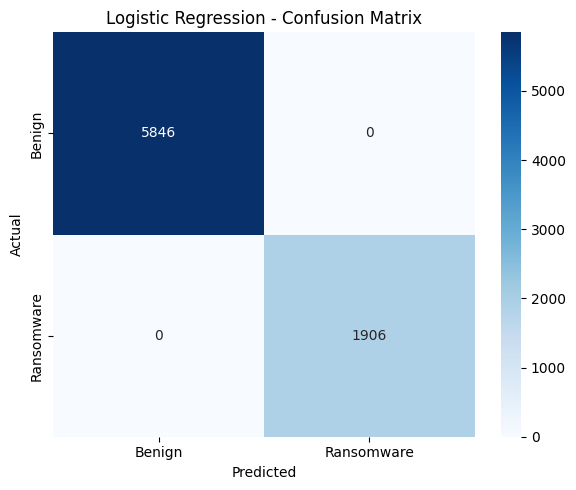

In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt

# Create model
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

# Train model
lr_model.fit(X_train_scaled, y_train)

# Make predictions
lr_predictions = lr_model.predict(X_test_scaled)

# Evaluate model
print("LOGISTIC REGRESSION RESULTS")
print("--------------------------------")

print("Accuracy:",
      accuracy_score(y_test, lr_predictions) * 100, "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    lr_predictions,
    target_names=['Benign', 'Ransomware']
))

# Confusion Matrix
cm = confusion_matrix(y_test, lr_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign', 'Ransomware'],
    yticklabels=['Benign', 'Ransomware']
)

plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('logistic_regression_cm.png', dpi=300)
plt.show()


Confusion Matrix:
[[5846    0]
 [   0 1906]]

Incorrect Predictions: 0


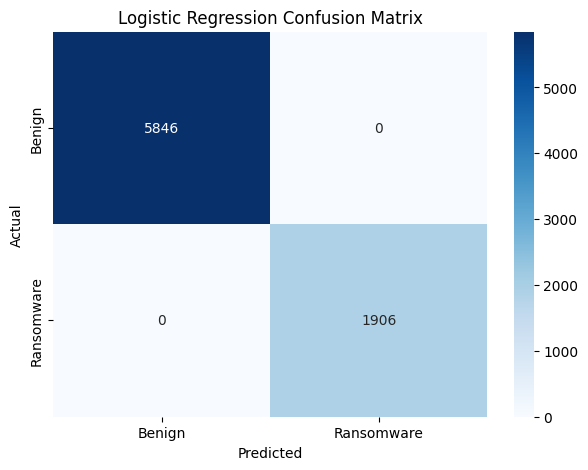

In [ ]:

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, lr_predictions)

print("Confusion Matrix:")
print(cm)

print("\nIncorrect Predictions:",
      (y_test != lr_predictions).sum())

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign', 'Ransomware'],
    yticklabels=['Benign', 'Ransomware']
)

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


In [ ]:

# Check whether original Class column
# directly reveals the target

print("Class vs Category:")
print(pd.crosstab(
    df_binary['Class'],
    df_binary['Target']
))

print("\nDuplicate feature rows:",
      X.duplicated().sum())

print("\nHighest feature correlations with target:")
correlations = X.corrwith(y).abs().sort_values(
    ascending=False
)

print(correlations.head(10))


Class vs Category:
Target       0     1
Class               
Benign   29231     0
Malware      0  9529

Duplicate feature rows: 6

Highest feature correlations with target:
dlllist.avg_dlls_per_proc    0.870126
handles.nsection             0.867076
handles.nevent               0.817433
handles.nthread              0.805971
handles.nmutant              0.783422
pslist.avg_threads           0.773163
handles.ntimer               0.765872
dlllist.ndlls                0.762912
handles.nsemaphore           0.724051
ldrmodules.not_in_load       0.692803
dtype: float64


/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [ ]:

# Identify constant features
constant_features = [
    col for col in X.columns
    if X[col].nunique() <= 1
]

print("Constant Features:", constant_features)

# Remove constant features
X_clean = X.drop(columns=constant_features)

print("\nFeatures Before:", X.shape[1])
print("Features After:", X_clean.shape[1])

# Check label columns are excluded
print("\nLeakage column check:")
print("Class in features:", 'Class' in X_clean.columns)
print("Category in features:", 'Category' in X_clean.columns)
print("Filename in features:", 'Filename' in X_clean.columns)


Constant Features: ['pslist.nprocs64bit', 'handles.nport', 'svcscan.interactive_process_services']

Features Before: 55
Features After: 52

Leakage column check:
Class in features: False
Category in features: False
Filename in features: False


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Handle infinite and missing values
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

imputer = SimpleImputer(strategy='median')

X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

print("Clean Data Prepared Successfully!")
print("Training:", X_train_scaled.shape)
print("Testing:", X_test_scaled.shape)


Clean Data Prepared Successfully!
Training: (31008, 52)
Testing: (7752, 52)


In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

lr_model.fit(X_train_scaled, y_train)

lr_predictions = lr_model.predict(X_test_scaled)

print("Verified Logistic Regression Accuracy:",
      accuracy_score(y_test, lr_predictions) * 100, "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    lr_predictions,
    target_names=['Benign', 'Ransomware']
))


Verified Logistic Regression Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00      5846
  Ransomware       1.00      1.00      1.00      1906

    accuracy                           1.00      7752
   macro avg       1.00      1.00      1.00      7752
weighted avg       1.00      1.00      1.00      7752



DECISION TREE RESULTS
----------------------------
Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00      5846
  Ransomware       1.00      1.00      1.00      1906

    accuracy                           1.00      7752
   macro avg       1.00      1.00      1.00      7752
weighted avg       1.00      1.00      1.00      7752



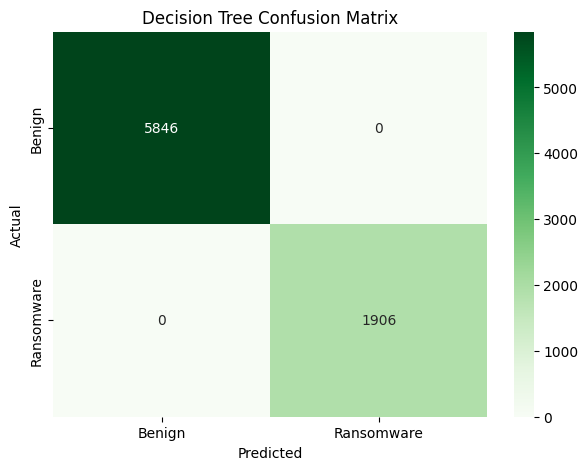

In [ ]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

# Create Decision Tree model
dt_model = DecisionTreeClassifier(
    max_depth=15,
    class_weight='balanced',
    random_state=42
)

# Train model
dt_model.fit(X_train_scaled, y_train)

# Prediction
dt_predictions = dt_model.predict(X_test_scaled)

# Evaluation
dt_accuracy = accuracy_score(y_test, dt_predictions)

print("DECISION TREE RESULTS")
print("----------------------------")
print("Accuracy:", dt_accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    dt_predictions,
    target_names=['Benign', 'Ransomware']
))

# Confusion Matrix
cm = confusion_matrix(y_test, dt_predictions)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Benign', 'Ransomware'],
    yticklabels=['Benign', 'Ransomware']
)

plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


RANDOM FOREST RESULTS
----------------------------
Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00      5846
  Ransomware       1.00      1.00      1.00      1906

    accuracy                           1.00      7752
   macro avg       1.00      1.00      1.00      7752
weighted avg       1.00      1.00      1.00      7752



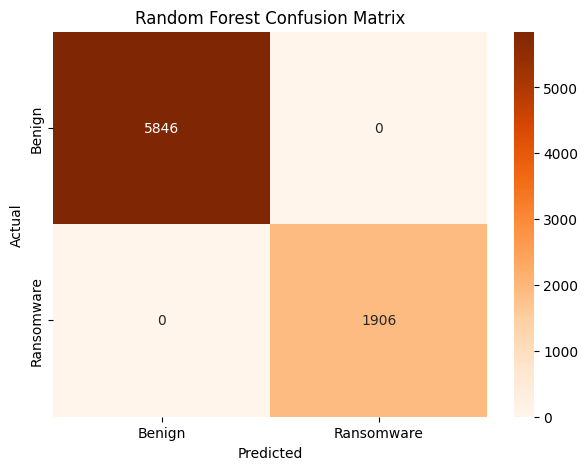

In [ ]:

from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train_scaled, y_train)

# Prediction
rf_predictions = rf_model.predict(X_test_scaled)

# Evaluation
rf_accuracy = accuracy_score(y_test, rf_predictions)

print("RANDOM FOREST RESULTS")
print("----------------------------")
print("Accuracy:", rf_accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_predictions,
    target_names=['Benign', 'Ransomware']
))

# Confusion Matrix
cm = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Benign', 'Ransomware'],
    yticklabels=['Benign', 'Ransomware']
)

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


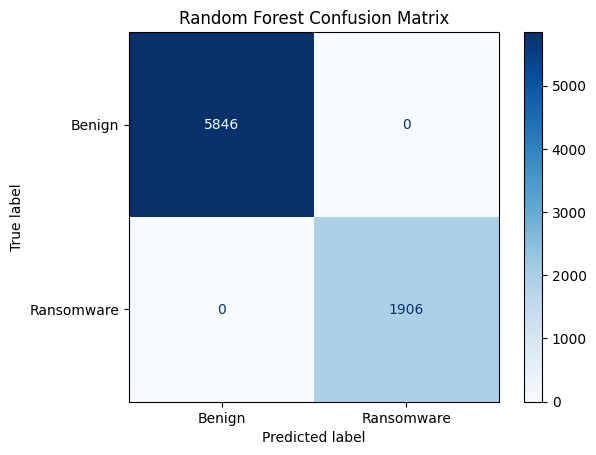

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

rf_cm = confusion_matrix(y_test, rf_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=['Benign', 'Ransomware']
)

disp.plot(cmap='Blues')
plt.title("Random Forest Confusion Matrix")
plt.show()

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

dt_model = DecisionTreeClassifier(
    max_depth=15,
    class_weight='balanced',
    random_state=42
)

dt_model.fit(X_train_scaled, y_train)

dt_predictions = dt_model.predict(X_test_scaled)

print("DECISION TREE RESULTS")
print("----------------------------")
print("Accuracy:", accuracy_score(y_test, dt_predictions) * 100, "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    dt_predictions,
    target_names=['Benign', 'Ransomware']
))

DECISION TREE RESULTS
----------------------------
Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00      5846
  Ransomware       1.00      1.00      1.00      1906

    accuracy                           1.00      7752
   macro avg       1.00      1.00      1.00      7752
weighted avg       1.00      1.00      1.00      7752



In [ ]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.metrics import accuracy_score, classification_report

# Build ANN model
ann_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

# Compile model
ann_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train model
history = ann_model.fit(
    X_train_scaled,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# Predictions
ann_probabilities = ann_model.predict(X_test_scaled)
ann_predictions = (ann_probabilities > 0.5).astype(int).ravel()

# Results
print("\nANN RESULTS")
print("----------------------------")
print("Accuracy:", accuracy_score(y_test, ann_predictions) * 100, "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    ann_predictions,
    target_names=['Benign', 'Ransomware']
))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
776/776 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9882 - loss: 0.0538 - val_accuracy: 0.9994 - val_loss: 0.0035
Epoch 2/20
776/776 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9982 - loss: 0.0137 - val_accuracy: 0.9997 - val_loss: 0.0012
Epoch 3/20
776/776 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9990 - loss: 0.0083 - val_accuracy: 0.9998 - val_loss: 5.8537e-04
Epoch 4/20
776/776 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9992 - loss: 0.0029 - val_accuracy: 1.0000 - val_loss: 1.7726e-04
Epoch 5/20
776/776 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9996 - loss: 0.0017 - val_accuracy: 1.0000 - val_loss: 1.7126e-04
Epoch 6/20
776/776 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9994 - loss: 0.0018 - val_accuracy: 1.0000 - val_loss: 1.7916e-04
Epoch 7/20
776/776 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9994 - loss: 0.0018 - val_accuracy: 1.0000 - val_loss: 7.5714e-05
Epoch 8/20
776/776 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9996 - loss: 0.001

MODEL PERFORMANCE COMPARISON
              Model  Accuracy (%)
Logistic Regression         100.0
      Random Forest         100.0
      Decision Tree         100.0
                ANN         100.0


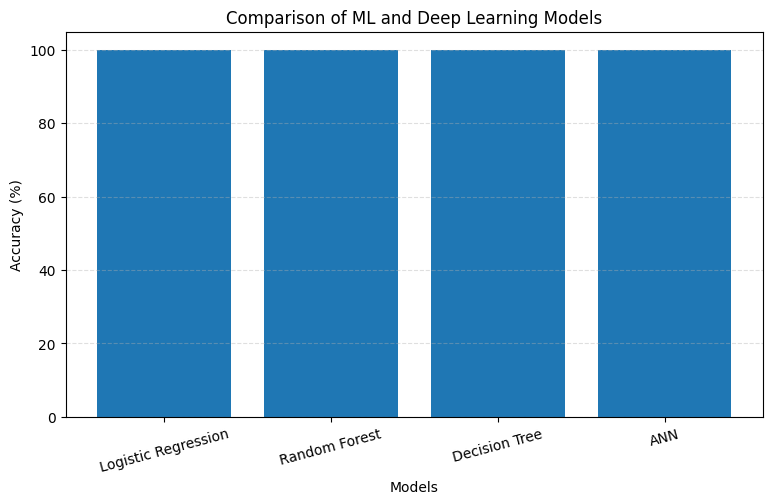

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

results = {
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'Decision Tree',
        'ANN'
    ],
    'Accuracy (%)': [
        accuracy_score(y_test, lr_predictions) * 100,
        accuracy_score(y_test, rf_predictions) * 100,
        accuracy_score(y_test, dt_predictions) * 100,
        accuracy_score(y_test, ann_predictions) * 100
    ]
}

comparison_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
print(comparison_df.to_string(index=False))

plt.figure(figsize=(9, 5))
plt.bar(comparison_df['Model'], comparison_df['Accuracy (%)'])
plt.title('Comparison of ML and Deep Learning Models')
plt.xlabel('Models')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 105)
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.show()


In [ ]:

import pandas as pd

# 1. Check target-related columns
print("LEAKAGE CHECK")
print("----------------------------")

forbidden_columns = ['Class', 'Category', 'Filename', 'Target']

print("Target-related columns in X:",
      [col for col in forbidden_columns if col in X_clean.columns])

# 2. Check identical feature records across train and test
train_hash = set(
    pd.util.hash_pandas_object(X_train, index=False)
)
test_hash = set(
    pd.util.hash_pandas_object(X_test, index=False)
)

common_records = train_hash.intersection(test_hash)

print("Identical feature records in both sets:", len(common_records))

# 3. Check duplicate feature records
print("Duplicate rows in training data:", X_train.duplicated().sum())
print("Duplicate rows in testing data:", X_test.duplicated().sum())

# 4. Check class distribution
print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


LEAKAGE CHECK
----------------------------
Target-related columns in X: []
Identical feature records in both sets: 3
Duplicate rows in training data: 3
Duplicate rows in testing data: 0

Training target distribution:
Target
0    23385
1     7623
Name: count, dtype: int64

Testing target distribution:
Target
0    5846
1    1906
Name: count, dtype: int64


In [ ]:

# Find exact overlapping feature rows
train_hashes = pd.util.hash_pandas_object(
    X_train, index=False
)

test_hashes = pd.util.hash_pandas_object(
    X_test, index=False
)

overlap_hashes = set(train_hashes).intersection(set(test_hashes))

print("Overlapping records:", len(overlap_hashes))

# Remove overlapping rows from test data
test_mask = ~test_hashes.isin(overlap_hashes)

X_test_clean = X_test.loc[test_mask]
y_test_clean = y_test.loc[test_mask]

# Prepare cleaned test data using existing fitted preprocessing
X_test_clean_imp = imputer.transform(X_test_clean)
X_test_clean_scaled = scaler.transform(X_test_clean_imp)

print("Original test size:", len(X_test))
print("Clean test size:", len(X_test_clean))


Overlapping records: 3
Original test size: 7752
Clean test size: 7749


In [ ]:

from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# Predictions on cleaned test data
lr_clean_pred = lr_model.predict(X_test_clean_scaled)
rf_clean_pred = rf_model.predict(X_test_clean_scaled)
dt_clean_pred = dt_model.predict(X_test_clean_scaled)

ann_clean_prob = ann_model.predict(X_test_clean_scaled)
ann_clean_pred = (ann_clean_prob > 0.5).astype(int).ravel()

# Compare results
clean_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'Decision Tree',
        'ANN'
    ],
    'Accuracy (%)': [
        accuracy_score(y_test_clean, lr_clean_pred) * 100,
        accuracy_score(y_test_clean, rf_clean_pred) * 100,
        accuracy_score(y_test_clean, dt_clean_pred) * 100,
        accuracy_score(y_test_clean, ann_clean_pred) * 100
    ]
})

print("CLEAN TEST DATA RESULTS")
print(clean_results.to_string(index=False))

print("\nANN Classification Report:")
print(classification_report(
    y_test_clean,
    ann_clean_pred,
    target_names=['Benign', 'Ransomware']
))


243/243 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
CLEAN TEST DATA RESULTS
              Model  Accuracy (%)
Logistic Regression         100.0
      Random Forest         100.0
      Decision Tree         100.0
                ANN         100.0

ANN Classification Report:
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00      5846
  Ransomware       1.00      1.00      1.00      1903

    accuracy                           1.00      7749
   macro avg       1.00      1.00      1.00      7749
weighted avg       1.00      1.00      1.00      7749



In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd
import numpy as np

# Hold out one complete ransomware family
held_out_family = 'Ransomware-Maze'

# Separate benign and ransomware records
benign_idx = df_binary[df_binary['Category'] == 'Benign'].index

ransomware_idx = df_binary[
    df_binary['Category'].str.startswith('Ransomware-', na=False)
].index

maze_idx = df_binary[
    df_binary['Category'] == held_out_family
].index

other_ransomware_idx = df_binary[
    (df_binary['Category'].str.startswith('Ransomware-', na=False)) &
    (df_binary['Category'] != held_out_family)
].index

# Split benign records separately
benign_train_idx, benign_test_idx = train_test_split(
    benign_idx,
    test_size=0.20,
    random_state=42
)

# Training: benign + all ransomware families except Maze
train_idx = list(benign_train_idx) + list(other_ransomware_idx)

# Testing: unseen Maze family + unseen benign records
test_idx = list(benign_test_idx) + list(maze_idx)

X_group_train = X_clean.loc[train_idx]
X_group_test = X_clean.loc[test_idx]

y_group_train = y.loc[train_idx]
y_group_test = y.loc[test_idx]

# Fit preprocessing only on training data
group_imputer = SimpleImputer(strategy='median')

X_group_train_imp = group_imputer.fit_transform(X_group_train)
X_group_test_imp = group_imputer.transform(X_group_test)

group_scaler = StandardScaler()

X_group_train_scaled = group_scaler.fit_transform(X_group_train_imp)
X_group_test_scaled = group_scaler.transform(X_group_test_imp)

print("Training records:", len(y_group_train))
print("Testing records:", len(y_group_test))
print("Unseen ransomware family:", held_out_family)

# Train and evaluate three ML models
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, max_depth=15,
        class_weight='balanced', random_state=42
    ),
    'Decision Tree': DecisionTreeClassifier(
        max_depth=15, class_weight='balanced', random_state=42
    )
}

group_results = []

for name, model in models.items():
    model.fit(X_group_train_scaled, y_group_train)
    predictions = model.predict(X_group_test_scaled)

    accuracy = accuracy_score(y_group_test, predictions) * 100
    group_results.append([name, accuracy])

    print(f"\n{name} Accuracy: {accuracy:.2f}%")
    print(classification_report(
        y_group_test, predictions,
        target_names=['Benign', 'Ransomware']
    ))

# Train ANN on the same family-separated data
group_ann = Sequential([
    tf.keras.Input(shape=(X_group_train_scaled.shape[1],)),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

group_ann.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

group_ann.fit(
    X_group_train_scaled,
    y_group_train,
    epochs=10,
    batch_size=32,
    verbose=1
)

ann_group_prob = group_ann.predict(X_group_test_scaled)
ann_group_pred = (ann_group_prob > 0.5).astype(int).ravel()

ann_group_accuracy = accuracy_score(
    y_group_test, ann_group_pred
) * 100

group_results.append(['ANN', ann_group_accuracy])

print("\nANN Unseen Family Accuracy:", round(ann_group_accuracy, 2), "%")

print("\nFINAL UNSEEN FAMILY COMPARISON")
print(pd.DataFrame(
    group_results,
    columns=['Model', 'Accuracy (%)']
).to_string(index=False))


Training records: 31159
Testing records: 7601
Unseen ransomware family: Ransomware-Maze

Logistic Regression Accuracy: 99.97%
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00      5847
  Ransomware       1.00      1.00      1.00      1754

    accuracy                           1.00      7601
   macro avg       1.00      1.00      1.00      7601
weighted avg       1.00      1.00      1.00      7601


Random Forest Accuracy: 100.00%
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00      5847
  Ransomware       1.00      1.00      1.00      1754

    accuracy                           1.00      7601
   macro avg       1.00      1.00      1.00      7601
weighted avg       1.00      1.00      1.00      7601


Decision Tree Accuracy: 99.89%
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00      5847
  Ransomware       1.00      1.00      1.00   

Random Forest Confusion Matrix:
[[5847    0]
 [   0 1754]]


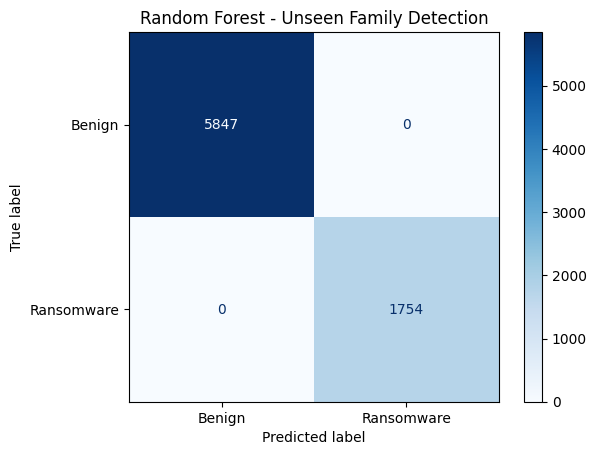

In [ ]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Random Forest predictions on unseen family test set
rf_group_model = models['Random Forest']

rf_group_predictions = rf_group_model.predict(
    X_group_test_scaled
)

# Confusion Matrix
cm = confusion_matrix(
    y_group_test,
    rf_group_predictions
)

print("Random Forest Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Benign', 'Ransomware']
)

disp.plot(cmap='Blues', values_format='d')
plt.title('Random Forest - Unseen Family Detection')
plt.show()


In [ ]:

import joblib
import tensorflow as tf

# Save Machine Learning models
joblib.dump(lr_model, 'logistic_regression.pkl')
joblib.dump(rf_model, 'random_forest.pkl')
joblib.dump(dt_model, 'decision_tree.pkl')

# Save preprocessing objects
joblib.dump(imputer, 'imputer.pkl')
joblib.dump(scaler, 'scaler.pkl')

# Save ANN model
ann_model.save('ransomware_ann.keras')

print("All models and preprocessing files saved successfully!")


All models and preprocessing files saved successfully!


In [ ]:

import zipfile

# Save feature names
joblib.dump(list(X_clean.columns), 'feature_names.pkl')

# Create ZIP file
files_to_save = [
    'logistic_regression.pkl',
    'random_forest.pkl',
    'decision_tree.pkl',
    'imputer.pkl',
    'scaler.pkl',
    'ransomware_ann.keras',
    'feature_names.pkl'
]

with zipfile.ZipFile('Ransomware_Detection_Models.zip', 'w') as zipf:
    for file in files_to_save:
        zipf.write(file)

print("ZIP file created successfully!")

# Download ZIP
from google.colab import files
files.download('Ransomware_Detection_Models.zip')


ZIP file created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install gradio

In [ ]:

import gradio as gr
import pandas as pd
import joblib

# Load trained model and preprocessing objects
rf_model = joblib.load('random_forest.pkl')
imputer = joblib.load('imputer.pkl')
scaler = joblib.load('scaler.pkl')
feature_names = joblib.load('feature_names.pkl')

# Prediction function
def detect_ransomware(file):
    if file is None:
        return "Please upload a CSV file.", None

    try:
        data = pd.read_csv(file)

        # Check required features
        missing = [
            col for col in feature_names
            if col not in data.columns
        ]

        if missing:
            return (
                "CSV format error. Required behavioral features are missing: "
                + ", ".join(missing[:10]),
                None
            )

        # Select features in correct order
        X_input = data[feature_names]

        # Preprocessing
        X_input = X_input.replace(
            [float('inf'), float('-inf')], float('nan')
        )

        X_imputed = imputer.transform(X_input)
        X_scaled = scaler.transform(X_imputed)

        # Prediction
        predictions = rf_model.predict(X_scaled)

        # Output table
        results = data.copy()
        results['Prediction'] = [
            'Ransomware' if value == 1 else 'Benign'
            for value in predictions
        ]

        ransomware_count = sum(predictions == 1)
        benign_count = sum(predictions == 0)

        summary = (
            f"Analysis Completed!\n\n"
            f"Total Records: {len(predictions)}\n"
            f"Benign Records: {benign_count}\n"
            f"Ransomware Records: {ransomware_count}"
        )

        return summary, results

    except Exception as e:
        return f"Error: {str(e)}", None


# Dashboard interface
with gr.Blocks(title="Ransomware Detection System") as demo:

    gr.Markdown("""
    # Ransomware Detection System
    ### Deep Learning-Based Ransomware Detection Using Behavioral Features

    Upload a CSV containing the required behavioral features
    to classify records as Benign or Ransomware.
    """)

    file_input = gr.File(
        label="Upload CSV Dataset",
        file_types=[".csv"],
        type="filepath"
    )

    analyze_btn = gr.Button(
        "Analyze Dataset",
        variant="primary"
    )

    output_summary = gr.Textbox(
        label="Detection Summary",
        lines=5
    )

    output_table = gr.Dataframe(
        label="Prediction Results"
    )

    analyze_btn.click(
        fn=detect_ransomware,
        inputs=file_input,
        outputs=[output_summary, output_table]
    )

    gr.Markdown("""
    **Note:** This is an academic research prototype.
    It requires CSV files containing the same 55 behavioral
    features used during model training. It is not a live
    ransomware scanner.
    """)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e9514179342c8a94d4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
